# CODEX tutorial: human intestine spatial proteomics

This tutorial runs GASTON-VI on human intestine CODEX spatial-proteomics data: 8
anatomical regions from duodenum to sigmoid colon, 8 donors per region (64
batches), 49 protein markers, 2,603,217 cells total. Protein intensities are not
sequencing counts, so this uses the `--likelihood gaussian` branch (see the
README's "Protein data" section) and a `--condition_file` so the model learns a
separate `h_m(d;c)` per anatomical region `c`.

In the intestine, protein abundance changes along the axis between the
muscularis (outer, smooth-muscle side) and the lumen (inner, epithelial side),
so we expect the isodepth to recover this axis.

A pretrained checkpoint and a small example tissue section are included in
`codex_example_data/`, so sections 3-5 below run immediately without needing to
retrain.

We will:

1. prepare the data (arcsinh + per-protein percentile-clip + per-protein
  min-max, each step computed separately within each anatomical region)
2. train the model (`--likelihood gaussian`, joint across all 64 batches)
3. load the pretrained model and plot the isodepth for one example section
4. compute the differential gradient score `DG_m` for all 49 proteins and rank
  them
5. look at the two proteins at opposite ends of that ranking, CD161 and CD66,
  across all 8 regions

## Data

Download `23_09_CODEX_HuBMAP_alldata_Dryad_merged.csv` from
[the Dryad record for Hickey et al. 2023, "Organization of the human intestine at
single-cell resolution"](https://datadryad.org/dataset/doi:10.5061/dryad.pk0p2ngrf)
(dataset DOI 10.5061/dryad.pk0p2ngrf; use the Sep 2023 version of the file, not the
Nov 2022 `CODEX_HuBMAP_alldata_Dryad.csv`). It is one per-cell CSV with columns
`donor`, `Tissue_location` (one of the 8 region names below), `Xcorr`, `Ycorr`, and
one column per protein marker (the 49 names in `MARKER_COLS` below).

Run this notebook from the `notebooks/` folder, and set the two paths below.

In [3]:
import glob
import sys

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, "..")
from gaston_vi.model.gaston_vi import GASTON_VI
from gaston_vi.preprocess.codex import preprocess_codex
from gaston_vi.analysis.differential_gradient import differential_gradient_score

plt.rcParams["figure.dpi"] = 150

RAW_CSV = "/path/to/intestine_codex_cells.csv"
DATA_DIR = "/path/to/intestine_codex"
RESULTS_DIR = "/path/to/results"
EXAMPLE_DIR = "codex_example_data"  # pretrained checkpoint + one example section, included

ModuleNotFoundError: No module named 'pandas'

## 1. Prepare the data

GASTON-VI's protein-data branch expects intensities that are already
arcsinh-transformed and min-max scaled to `[0, 1]`, with both steps computed
separately for each anatomical region (not across the whole dataset) -- see
`gaston_vi/preprocess/codex.py`. There is no library-size concept for intensity
data, so unlike the count-data tutorials this does not save or use a library
size.

This cell:

1. Reads the per-cell table and keeps the 8 regions below.
2. Assigns each cell a `condition` (its region, `0`-`7`) and a `batch`
  (region, donor pair, `0`-`63`), so the model learns one `h_m(d;c)` per region
  while still aligning isodepth across all 64 sections.
3. Scales each region's protein intensities independently with
  `preprocess_codex`.
4. Saves the five arrays `train.py` reads.

In [1]:
TISSUE_ORDER = ["Duodenum", "Proximal Jejunum", "Mid-jejunum", "Ileum",
                "Ascending", "Transverse", "Descending", "Descending - Sigmoid"]
MARKER_COLS = [
    "MUC2", "MUC1", "CD31", "CD49f", "CD15", "CHGA", "ITLN1", "CD4", "CD127",
    "Vimentin", "HLADR", "CD8", "CD11c", "CD44", "CD16", "BCL2", "CD3", "CD123",
    "CD38", "CD90", "aSMA", "CD21", "NKG2D", "CD66", "CD57", "CD206", "CD68",
    "CD34", "aDef5", "CD7", "CD36", "CD138", "CD45RO", "CD117", "CD19",
    "Podoplanin", "CD45", "CD56", "CD69", "Ki67", "CD49a", "CD163", "CD161",
    "OLFM4", "FAP", "CD25", "CollIV", "CK7", "MUC6",
]

df = pd.read_csv(RAW_CSV, usecols=["donor", "Tissue_location", "Xcorr", "Ycorr"] + MARKER_COLS)
df = df[df["Tissue_location"].isin(TISSUE_ORDER)].copy()

condition_of = {t: i for i, t in enumerate(TISSUE_ORDER)}
donors = sorted(df["donor"].unique())
donor_of = {d: i for i, d in enumerate(donors)}
df["condition"] = df["Tissue_location"].map(condition_of)
df["batch"] = df["condition"] * len(donors) + df["donor"].map(donor_of)

coords = df[["Xcorr", "Ycorr"]].to_numpy(dtype=np.float32)
condition = df["condition"].to_numpy(dtype=np.int64)
batch = df["batch"].to_numpy(dtype=np.int64)

scaled = np.zeros((len(df), len(MARKER_COLS)), dtype=np.float32)
for region, c in condition_of.items():
    rows = (df["condition"] == c).to_numpy()
    scaled[rows], _ = preprocess_codex(df.loc[rows, MARKER_COLS].to_numpy())

np.save(f"{DATA_DIR}/coords_mat.npy", coords)
np.save(f"{DATA_DIR}/counts_mat.npy", scaled)
np.save(f"{DATA_DIR}/protein_names.npy", np.array(MARKER_COLS))
np.save(f"{DATA_DIR}/batch_vector.npy", batch)
np.save(f"{DATA_DIR}/condition_vector.npy", condition)
print(f"{len(df)} cells, {len(MARKER_COLS)} proteins, "
      f"{len(donors)} donors x {len(TISSUE_ORDER)} regions = {batch.max() + 1} batches")

## 2. Train

`--likelihood gaussian` selects the protein branch (no library-size scaling, no
softmax -- see the README). `--condition_file` makes the decoder learn a
separate `h_m(d;c)` per region; `--batch_file` keeps every donor's isodepth on a
comparable scale via `--batch_align_weight`. This is a joint fit across all
2.6M cells and 64 batches; on a single GPU this takes about 14 hours, so for
most purposes skip straight to section 3 and use the included pretrained
checkpoint instead. See `train.slurm` for running this on a cluster.

In [1]:
!python ../train.py \
    --coords_file {DATA_DIR}/coords_mat.npy \
    --counts_file {DATA_DIR}/counts_mat.npy \
    --gene_names_file {DATA_DIR}/protein_names.npy \
    --batch_file {DATA_DIR}/batch_vector.npy \
    --condition_file {DATA_DIR}/condition_vector.npy \
    --likelihood gaussian \
    --z_dim 8 --batch_size 4096 --batch_align_weight 0.1 \
    --results_dir {RESULTS_DIR} 2>&1 | tail -n 1

## 3. Load the pretrained model and plot the isodepth

`codex_example_data/codex_model_rep1.pt` is a GASTON-VI checkpoint trained on
the full dataset as in section 2. `f_logits(d, condition=c)` gives the
pre-decoder spatial logits for region `c` -- the Gaussian branch's decoder
returns these directly as `h_m(d;c)`, with no softmax (see the README's
"Protein data" note).

We also load one example section (duodenum, donor B004, 44,170 cells) with its
trained isodepth, to plot without needing the full 2.6M-cell dataset on hand.

In [1]:
checkpoint = torch.load(f"{EXAMPLE_DIR}/codex_model_rep1.pt", map_location="cpu", weights_only=False)
model_kwargs = dict(checkpoint["model_kwargs"])
model_kwargs.setdefault("likelihood", "gaussian")  # this checkpoint predates that field being saved
model = GASTON_VI(**model_kwargs)
model.load_state_dict(checkpoint["state_dict"], strict=False)
model.eval()
protein_names = [str(g) for g in checkpoint["gene_names"]]

def h_of_d(values, condition_idx):
    with torch.no_grad():
        return model.decoder.f_logits(
            torch.tensor(values, dtype=torch.float32)[:, None], condition=condition_idx
        ).numpy()

section = np.load(f"{EXAMPLE_DIR}/example_section_duodenum_B004.npz")
coords, isodepth = section["coords"], section["isodepth"]
print(f"{len(protein_names)} proteins, {len(coords)} cells in example section")

Per-batch spatial encoders: 64 encoders per isodepth axis
Decoder: linear_hz
scVI encoders batch-conditioned: n_batches=64
f(d) conditioned on condition: n_conditions=8 (separate zonation curve per condition)
49 proteins, 44170 cells in example section


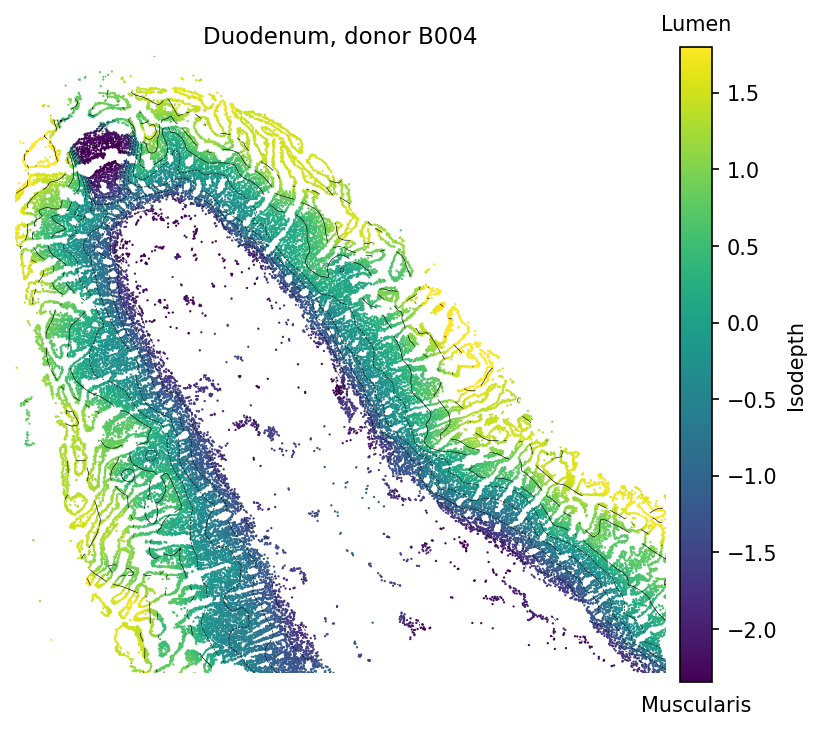

In [1]:
lo, hi = np.percentile(isodepth, [1, 99])

triangulation = mtri.Triangulation(coords[:, 0], coords[:, 1])
corners = coords[triangulation.triangles]
edges = np.stack([corners[:, 1] - corners[:, 0], corners[:, 2] - corners[:, 1],
                  corners[:, 0] - corners[:, 2]], axis=1)
longest = np.linalg.norm(edges, axis=2).max(axis=1)
triangulation.set_mask(longest > 3 * np.median(longest))

fig, ax = plt.subplots(figsize=(6, 5.5))
points = ax.scatter(*coords.T, c=isodepth, vmin=lo, vmax=hi, cmap="viridis",
                    s=1.2, linewidths=0, rasterized=True)
ax.tricontour(triangulation, isodepth, levels=np.linspace(lo, hi, 10),
              colors="black", linewidths=0.3)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Duodenum, donor B004", fontsize=11)

colorbar = fig.colorbar(points, ax=ax, fraction=0.046, pad=0.02)
colorbar.set_label("Isodepth")
colorbar.ax.text(0.5, 1.02, "Lumen", transform=colorbar.ax.transAxes, ha="center", va="bottom")
colorbar.ax.text(0.5, -0.02, "Muscularis", transform=colorbar.ax.transAxes, ha="center", va="top")
plt.show()

## 4. Differential gradient score

`DG_m` (paper Appendix S3.2) measures how much the shape of a protein's spatial
abundance function `h_m(d;c)` differs across the 4 conditions within one tissue
group: z-score each region's `h_m(d;c)` curve, take the variance across the 4
conditions at each `d`, and average over `d`. A high `DG_m` means `h_m(d;c)`
takes on a genuinely different shape per region; a low `DG_m` means its shape
is essentially shared. We compute it separately for the small intestine
(regions 0-3) and the colon (regions 4-7), and rank all 49 proteins by it in
each group.

In [1]:
D_GRID = np.linspace(-2.5, 2.5, 200).astype(np.float32)
h = np.stack([h_of_d(D_GRID, c) for c in range(8)])  # (8 regions, 200, 49 proteins)
dg_si = differential_gradient_score(h[:4])
dg_colon = differential_gradient_score(h[4:])

order_si = np.argsort(-dg_si)
print("Top 5 by DG_m, small intestine:")
for i in order_si[:5]:
    print(f"  {protein_names[i]:12s} DG_m = {dg_si[i]:.2f}")
print("Bottom 5 by DG_m, small intestine:")
for i in order_si[-5:]:
    print(f"  {protein_names[i]:12s} DG_m = {dg_si[i]:.2f}")

Top 5 by DG_m, small intestine:
  MUC1         DG_m = 0.87
  CD25         DG_m = 0.85
  CD161        DG_m = 0.83
  Ki67         DG_m = 0.82
  ITLN1        DG_m = 0.74
Bottom 5 by DG_m, small intestine:
  aSMA         DG_m = 0.12
  CD34         DG_m = 0.12
  CD90         DG_m = 0.10
  HLADR        DG_m = 0.09
  CD31         DG_m = 0.09


## 5. CD161 vs. CD66 across all 8 regions

CD161 and CD66 sit at opposite ends of the ranking above -- CD161 near the top
(a genuinely differential gradient across regions), CD66 near the bottom (a
largely shared one). The cell below prints their exact ranks, then plots the
spatial protein abundance function `h_m(d;c)` for each region `c`, z-scored
(mean 0, std 1) so every panel shows the shape of `h_m(d;c)` alone, independent
of that region's absolute scale. Blue shades are the 4 small-intestine regions,
red shades are the 4 colon regions.

In [1]:
for marker in ["CD161", "CD66"]:
    g = protein_names.index(marker)
    rank_si = int((dg_si > dg_si[g]).sum()) + 1
    rank_colon = int((dg_colon > dg_colon[g]).sum()) + 1
    print(f"{marker}: DG_m = {dg_si[g]:.2f} (rank {rank_si}/{len(protein_names)} in the small intestine), "
          f"DG_m = {dg_colon[g]:.2f} (rank {rank_colon}/{len(protein_names)} in the colon)")

CD161: DG_m = 0.83 (rank 3/49 in the small intestine), DG_m = 0.65 (rank 11/49 in the colon)
CD66: DG_m = 0.16 (rank 40/49 in the small intestine), DG_m = 0.04 (rank 48/49 in the colon)


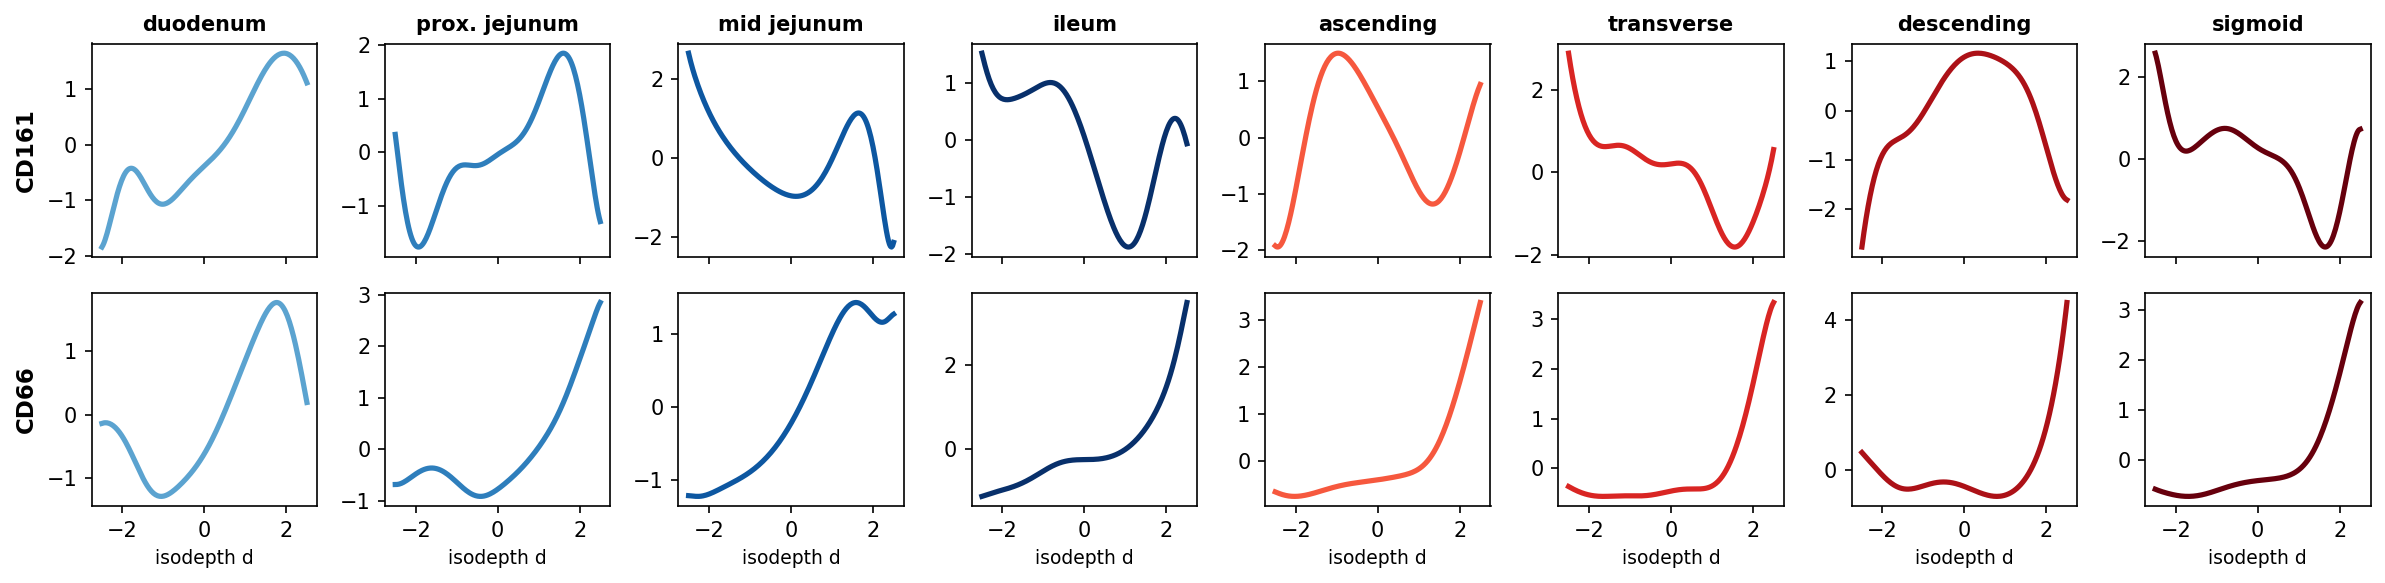

In [1]:
TISSUE_TITLES = ["duodenum", "prox. jejunum", "mid jejunum", "ileum",
                  "ascending", "transverse", "descending", "sigmoid"]
_samp = np.linspace(0.55, 1.0, 4)
COLORS = ([plt.get_cmap("Blues")(x) for x in _samp]
          + [plt.get_cmap("Reds")(x) for x in _samp])

fig, axes = plt.subplots(2, 8, figsize=(16, 4), sharex=True)
for row, marker in enumerate(["CD161", "CD66"]):
    g = protein_names.index(marker)
    for c in range(8):
        curve = h[c, :, g]
        curve_z = (curve - curve.mean()) / (curve.std() + 1e-8)
        ax = axes[row, c]
        ax.plot(D_GRID, curve_z, color=COLORS[c], lw=2.5)
        if row == 0:
            ax.set_title(TISSUE_TITLES[c], fontsize=10, fontweight="bold")
        if c == 0:
            ax.set_ylabel(marker, fontsize=11, fontweight="bold")
        if row == 1:
            ax.set_xlabel("isodepth d", fontsize=9)
fig.tight_layout()
plt.show()